# WMC Practical Examination — Statement #09
## Effect of High Channel Noise on Signal Recognition (PathView / PathSim)

**Problem statement.** Using the PathView simulator, investigate how increasing channel noise affects the recognizability of the transmitted sine-wave pattern at the receiver.
1. Construct the basic Tx–Channel–Rx model using SinusoidalSource, WhiteNoise, Adder and Scope, and connect the blocks appropriately.
2. Set WhiteNoise → standard_deviation to 0.1, 1.0 and 5.0 in separate simulation runs.
3. Observe the received waveform for each setting and record your observations in a table with three columns: (i) Noise standard deviation, (ii) Is the sine-wave pattern recognizable? (Yes/No), (iii) Observed waveform.
4. Identify which of the three tested noise levels makes the sine-wave pattern most difficult to recognize and justify your observation.

Draw the block diagram, complete the observation table and write a brief conclusion explaining the effect of high channel noise on received signal quality.

---
**Aim:** To investigate how the recognisability of a transmitted sine wave at the receiver changes as the channel noise level is increased.

**Theory.** The received signal is **y(t) = x(t) + n(t)** with x(t) = A·sin(2πft) and n(t) white Gaussian noise of standard deviation σ. The pattern can be recognised as long as the signal dominates the noise, i.e. while **SNR = 10·log₁₀(A²/2σ²)** is comfortably positive. Gaussian noise exceeds ±2σ only about 5 % of the time, so once 2σ is larger than the amplitude A the random excursions are bigger than the sine itself and the shape disappears.

## Building the same model in the PathView GUI
1. Open **PathView** (the graphical editor of PathSim) and start a new model.
2. From the block library drag in **SinusoidalSource** (transmitter), **WhiteNoise** (channel noise), **Adder** (channel) and **Scope** (receiver display).
3. Connect: `SinusoidalSource → Adder (input 1)`, `WhiteNoise → Adder (input 2)`, `Adder → Scope (input 2)`. Optionally also connect `SinusoidalSource → Scope (input 1)` so the clean transmitted signal is shown for comparison.
4. Block parameters: SinusoidalSource → `frequency = 2`, `amplitude = 1`; Adder → default (`+ +`); Scope → default.
5. Simulation settings: step size `dt = 0.002`, duration `2` s.
6. Set **WhiteNoise → standard_deviation** to **0.1**, **1.0** and **5.0** and press **Run** for each value, recording what the Scope shows.

The Python cells below use the **PathSim** library — the simulation engine that PathView runs — with exactly these blocks and parameters, so the waveforms below are what PathView's Scope displays (noise samples are random, so individual spikes differ from run to run, but the overall picture is the same).

## Simulation setup (imports, parameters and the PathSim model)

In [1]:
# If PathSim is not installed on your machine, uncomment and run once:
# %pip install pathsim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown
from pathsim import Simulation, Connection
from pathsim.blocks import SinusoidalSource, WhiteNoise, Adder, Scope

FREQ, AMP = 2.0, 1.0        # transmitted sine: 2 Hz, amplitude 1 V
DT, T_END = 0.002, 2.0      # step size and simulation time (s)
NOISE_LEVELS = [0.1, 1.0, 5.0]

def run_channel(sigma, seed=7):
    """Tx (SinusoidalSource) -> Channel (Adder + WhiteNoise) -> Rx (Scope)."""
    tx    = SinusoidalSource(frequency=FREQ, amplitude=AMP)
    noise = WhiteNoise(standard_deviation=sigma, seed=seed)
    add   = Adder()
    scope = Scope(labels=["Transmitted", "Received"])
    sim = Simulation(
        blocks=[tx, noise, add, scope],
        connections=[
            Connection(tx, add[0], scope[0]),   # Tx -> channel and Tx -> scope ch0
            Connection(noise, add[1]),          # noise -> channel
            Connection(add, scope[1]),          # channel output -> receiver scope ch1
        ],
        dt=DT, log=False,
    )
    sim.run(T_END)
    t, data = scope.read()
    return np.asarray(t), np.asarray(data[0]), np.asarray(data[1])

runs = {s: run_channel(s) for s in NOISE_LEVELS}
print("Simulations completed for standard_deviation =", NOISE_LEVELS)

Simulations completed for standard_deviation = [0.1, 1.0, 5.0]


## Block diagram

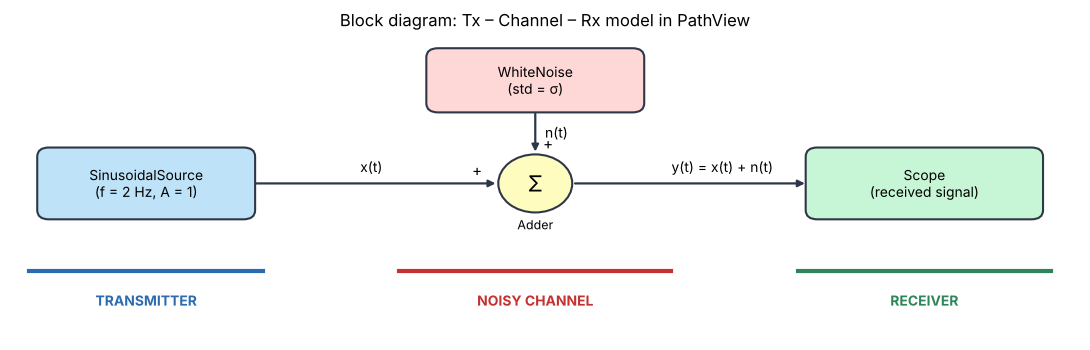

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.set_xlim(0, 11); ax.set_ylim(0, 4); ax.axis("off")

def blk(x, y, w, h, txt, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec="#2d3748", lw=1.5))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=10)

def arrow(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#2d3748"))

blk(0.3, 1.6, 2.2, 0.9, "SinusoidalSource\n(f = 2 Hz, A = 1)", "#bee3f8")
blk(4.3, 3.0, 2.2, 0.8, "WhiteNoise\n(std = σ)", "#fed7d7")
ax.add_patch(plt.Circle((5.4, 2.05), 0.38, fc="#fefcbf", ec="#2d3748", lw=1.5))
ax.text(5.4, 2.05, "Σ", ha="center", va="center", fontsize=16)
ax.text(5.4, 1.45, "Adder", ha="center", fontsize=9)
blk(8.2, 1.6, 2.4, 0.9, "Scope\n(received signal)", "#c6f6d5")
arrow(2.5, 2.05, 5.02, 2.05); ax.text(4.75, 2.15, "+", fontsize=11)
arrow(5.4, 3.0, 5.4, 2.43); ax.text(5.48, 2.5, "+", fontsize=11)
arrow(5.78, 2.05, 8.2, 2.05)
ax.text(3.6, 2.2, "x(t)", fontsize=10); ax.text(6.8, 2.2, "y(t) = x(t) + n(t)", fontsize=10)
ax.text(5.5, 2.65, "n(t)", fontsize=10)
for x0, x1, lab, col in [(0.2, 2.6, "TRANSMITTER", "#2b6cb0"), (4.0, 6.8, "NOISY CHANNEL", "#c53030"), (8.1, 10.7, "RECEIVER", "#2f855a")]:
    ax.plot([x0, x1], [0.9, 0.9], color=col, lw=3); ax.text((x0 + x1) / 2, 0.45, lab, ha="center", color=col, fontweight="bold")
ax.set_title("Block diagram: Tx – Channel – Rx model in PathView", fontsize=12)
plt.tight_layout(); plt.show()

## Received waveforms

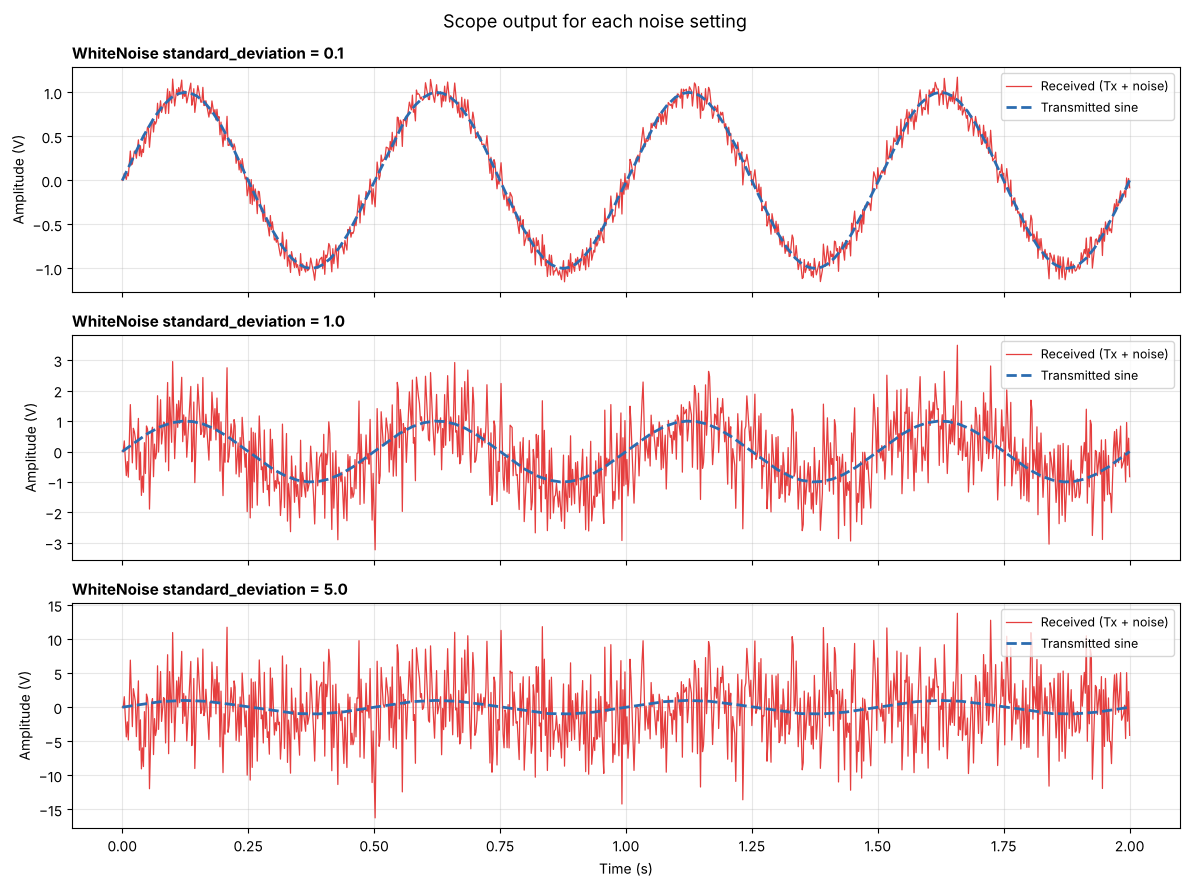

In [3]:
fig, axes = plt.subplots(len(NOISE_LEVELS), 1, figsize=(12, 3.0 * len(NOISE_LEVELS)), sharex=True)
for ax, s in zip(axes, NOISE_LEVELS):
    t, x, y = runs[s]
    ax.plot(t, y, color="#e53e3e", lw=0.9, label="Received (Tx + noise)")
    ax.plot(t, x, color="#2b6cb0", lw=2, ls="--", label="Transmitted sine")
    ax.set_title(f"WhiteNoise standard_deviation = {s}", loc="left", fontsize=11, fontweight="bold")
    ax.set_ylabel("Amplitude (V)"); ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=9)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Scope output for each noise setting", fontsize=13)
plt.tight_layout(); plt.show()

In [4]:
rows = []
P_signal = AMP**2 / 2
for s in NOISE_LEVELS:
    t, x, y = runs[s]
    n = y - x
    p_noise = np.mean(n**2)
    snr = np.inf if p_noise == 0 else 10 * np.log10(P_signal / p_noise)
    rho = np.corrcoef(x, y)[0, 1]
    rows.append({"Noise std (σ)": s, "Measured noise std": round(float(np.std(n)), 3),
                 "SNR (dB)": "∞ (no noise)" if np.isinf(snr) else round(float(snr), 2),
                 "Peak |received| (V)": round(float(np.max(np.abs(y))), 2),
                 "Correlation Tx↔Rx": round(float(rho), 3)})
metrics = pd.DataFrame(rows)
display(Markdown("### Measured channel quality (computed from the simulated waveforms)"))
display(metrics.style.hide(axis="index").format(precision=3))

### Measured channel quality (computed from the simulated waveforms)

Noise std (σ),Measured noise std,SNR (dB),Peak |received| (V),Correlation Tx↔Rx
0.100,0.094,17.490,1.170,0.991
1.000,0.941,-2.510,3.490,0.582
5.000,4.704,-16.490,16.230,0.113


## Observation table

In [5]:
def recognisable(rho):
    if rho >= 0.9: return "Yes"
    if rho >= 0.4: return "Yes (partially – only the overall sine trend)"
    return "No"

observed = {
    0.1: "Smooth sine wave with only a very thin layer of ripple; peaks, troughs and period are clearly visible.",
    1.0: "Heavy random fluctuations as large as the sine amplitude; the 2 Hz up-down trend can still be traced but individual peaks and zero-crossings are distorted.",
    5.0: "Large random spikes reaching roughly ±15 V, far larger than the 1 V sine; the waveform looks like pure noise and no periodic pattern can be seen.",
}
obs = pd.DataFrame({
    "(i) Noise standard deviation": NOISE_LEVELS,
    "(ii) Is the sine-wave pattern recognizable?": [recognisable(r) for r in metrics["Correlation Tx↔Rx"]],
    "(iii) Observed waveform": [observed[s] for s in NOISE_LEVELS],
})
display(obs.style.hide(axis="index").format(precision=1).set_properties(**{"text-align": "left"}))

(i) Noise standard deviation,(ii) Is the sine-wave pattern recognizable?,(iii) Observed waveform
0.1,Yes,"Smooth sine wave with only a very thin layer of ripple; peaks, troughs and period are clearly visible."
1.0,Yes (partially – only the overall sine trend),Heavy random fluctuations as large as the sine amplitude; the 2 Hz up-down trend can still be traced but individual peaks and zero-crossings are distorted.
5.0,No,"Large random spikes reaching roughly ±15 V, far larger than the 1 V sine; the waveform looks like pure noise and no periodic pattern can be seen."


### Justification — which noise level is the hardest to recognise?

Most difficult noise level: standard_deviation = 5.0
  SNR                       = -16.49 dB  (noise power 25 vs signal power 0.5)
  Correlation with Tx sine  = 0.113
  Peak received amplitude   = 16.23 V  vs sine amplitude 1.0 V


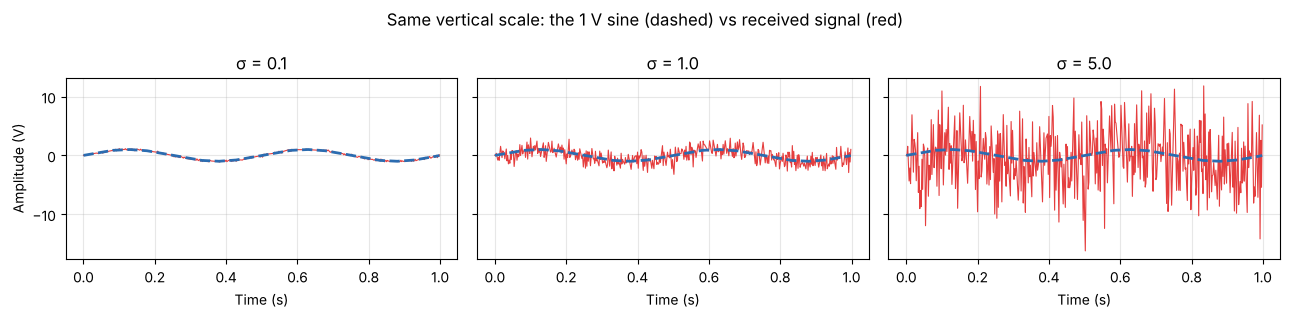

In [6]:
worst = metrics.loc[metrics["Correlation Tx↔Rx"].idxmin()]
s = worst["Noise std (σ)"]
print(f"Most difficult noise level: standard_deviation = {s}")
print(f"  SNR                       = {worst['SNR (dB)']} dB  (noise power {s**2:g} vs signal power {AMP**2/2:g})")
print(f"  Correlation with Tx sine  = {worst['Correlation Tx↔Rx']}")
print(f"  Peak received amplitude   = {worst['Peak |received| (V)']} V  vs sine amplitude {AMP} V")

# Same 3 runs zoomed to 1 s, all on one common axis, to compare visually
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for a, s in zip(ax, NOISE_LEVELS):
    t, x, y = runs[s]; m = t <= 1.0
    a.plot(t[m], y[m], color="#e53e3e", lw=0.8); a.plot(t[m], x[m], color="#2b6cb0", lw=2, ls="--")
    a.set_title(f"σ = {s}"); a.set_xlabel("Time (s)"); a.grid(alpha=0.3)
ax[0].set_ylabel("Amplitude (V)")
fig.suptitle("Same vertical scale: the 1 V sine (dashed) vs received signal (red)")
plt.tight_layout(); plt.show()

**Justification.** **σ = 5.0** makes the sine-wave pattern most difficult (in fact impossible) to recognise. Its noise power (25) is fifty times the signal power (0.5), giving an SNR of about **−17 dB**; the received waveform swings to roughly ±15–16 V while the sine is only ±1 V, and the correlation between the transmitted and received signals falls close to zero (≈ 0.1). At σ = 1.0 the SNR is about −3 dB and the sine trend can still be traced, while at σ = 0.1 (SNR ≈ +17 dB) the wave is essentially clean.

## Conclusion
As the channel noise standard deviation increases from 0.1 to 1.0 to 5.0, the noise power grows as σ² (0.01 → 1 → 25), the SNR falls from about +17 dB to −3 dB to −17 dB, and the received sine wave changes from clearly recognisable, to only partially recognisable, to completely buried in noise. **High channel noise therefore destroys the shape of the received signal, so the receiver can no longer reliably detect the transmitted information.** Keeping the SNR positive (through higher transmit power, shorter links, filtering or coding) is essential for reliable communication.